# 11 · Shot-aware tuning (1000 and 10 000 shots)

Notebook 10 tuned every quantum model on **exact** kernels. Some of the chosen settings (large C, small f) exploit
tiny kernel differences that finite-shot measurements cannot resolve, so those models collapse with 1000 shots.

Here hyperparameters are chosen the way they would be on hardware: **every kernel entry used in cross-validation,
training and evaluation is a finite-shot estimate** with the same budget B ∈ {1000, 10 000}.
Same frozen configurations, same 5 training subsamples, same confirmation file as notebook 10; each model is evaluated on it once.
Classical models do not depend on shots and are taken from notebook 10.

In [1]:
from matplotlib.lines import Line2D
import sys
sys.path.insert(0, "src")

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

from jet_data import (load_jets, select_quark_gluon, feature_matrix, event_level_split, balanced_subsample,
                      leading_constituents, BOOKKEEPING, PF_KEYS)
from kernels import (KERNELS, preprocess, onep1q_states, onep1q_kernel, angle_kernel, shot_noise)
from figure_style import set_style, save, COLORS

set_style()
SEED = 42
SEEDS = [0, 1, 2, 3, 4]
N_PER_CLASS = 200
N_CONST = 10
QGL_INPUTS = ("QG_mult", "QG_ptD", "QG_axis2")
C_GRID = np.logspace(-2, 6, 9)                       # 0.01 ... 1e6 (concentrated kernels may need large C)
F_GRID = np.round(np.logspace(0, 2.5, 12), 2)        # 1 ... 316
SHOTS = [100, 1000]
MAX_ITER = 200_000                                  # caps solver time at very large C; unconverged fits just score worse in CV
DEV_PATH = Path("Data/JetNtuple_RunIISummer16_13TeV_MC_1.h5")
CONFIRM_PATH = Path("Data/JetNtuple_RunIISummer16_13TeV_MC_10.h5")   # second, never-used file of record 12100
RESULTS = Path("results")
assert CONFIRM_PATH.exists(), f"confirmation file not found: {CONFIRM_PATH}"

COLUMNS = QGL_INPUTS + ("jetPt", "jetQGl")
def load(path):
    jets = select_quark_gluon(load_jets(path=path, features=COLUMNS, extra=BOOKKEEPING + PF_KEYS), require_loose_id=True)
    z, de, dp, _ = leading_constituents(jets, n_max=N_CONST)
    return {"y": jets["label"], "X": feature_matrix(jets, features=QGL_INPUTS), "pt": np.asarray(jets["jetPt"], float),
            "qgl": np.asarray(jets["jetQGl"], float), "z": z, "de": de, "dp": dp, "dr": np.sqrt(de**2 + dp**2), "jets": jets}

dev = load(DEV_PATH)
conf = load(CONFIRM_PATH)
train, test = event_level_split(dev["jets"], test_fraction=0.3, seed=SEED)
dev_test = np.flatnonzero(test)
print(f"development file: {len(dev['y'])} jets (train {int(train.sum())}, test {len(dev_test)})")
print(f"confirmation file: {len(conf['y'])} jets, quark fraction {conf['y'].mean():.3f}")

development file: 13912 jets (train 9729, test 4183)
confirmation file: 69810 jets, quark fraction 0.372


In [2]:
# name -> (family, how to build the kernel)
QUANTUM = {
    "amplitude, raw":            ("amplitude", "qgl", "raw"),
    "amplitude, standardised":   ("amplitude", "qgl", "standard"),
    "amplitude, min-max":        ("amplitude", "qgl", "minmax"),
    "angle, robust + YJ":        ("angle", "qgl", "robust_yj"),
    "angle, min-max":            ("angle", "qgl", "minmax"),
    "1P1Q (original)":           ("1P1Q", "const", "original"),
    "1P1Q rotation-invariant":   ("1P1Q", "const", "invariant"),
}

def kernel_builder(name, train_idx, f=None):
    family, inputs, variant = QUANTUM[name]
    if inputs == "qgl":
        Xtr = dev["X"][train_idx]
        def transform(X):
            return preprocess(variant, Xtr, X)[1]
        A = transform(Xtr)
        k = KERNELS[family]
        return lambda D, rows: k(transform(D["X"][rows]), A), k(A, A)
    if variant == "original":
        st = lambda D, rows: onep1q_states(D["z"][rows], D["de"][rows], D["dp"][rows], f)
        SA = st(dev, train_idx)
        return lambda D, rows: onep1q_kernel(st(D, rows), SA), onep1q_kernel(SA, SA)
    ang = lambda D, rows: f * D["z"][rows] * D["dr"][rows]
    A = ang(dev, train_idx)
    return lambda D, rows: angle_kernel(ang(D, rows), A), angle_kernel(A, A)

def cv_auc(K, labels, folds, C):
    out = []
    for tr, va in folds:
        svc = SVC(kernel="precomputed", C=C, max_iter=MAX_ITER).fit(K[np.ix_(tr, tr)], labels[tr])
        out.append(roc_auc_score(labels[va], svc.decision_function(K[np.ix_(va, tr)])))
    return np.mean(out)
print(list(QUANTUM))

['amplitude, raw', 'amplitude, standardised', 'amplitude, min-max', 'angle, robust + YJ', 'angle, min-max', '1P1Q (original)', '1P1Q rotation-invariant']


## 1. Tune and evaluate with finite-shot kernels (about 15–25 minutes; progress printed per model)

In [3]:
BUDGETS = [1000, 10000]
conf_all = np.arange(len(conf["y"]))
records = []
for s in SEEDS:
    idx = balanced_subsample(dev["y"], train, N_PER_CLASS, seed=s)
    y_tr = dev["y"][idx]
    folds = list(StratifiedKFold(5, shuffle=True, random_state=s).split(idx, y_tr))
    for name, (family, inputs, variant) in QUANTUM.items():
        f_options = F_GRID if family == "1P1Q" else [None]
        for B in BUDGETS:
            rng = np.random.default_rng(5000 + 17 * s + B)
            best = (-1, None, None, None)
            for f in f_options:
                _, K_tr = kernel_builder(name, idx, f)
                K_tr_n = shot_noise(K_tr, B, rng, symmetric=True)
                for C in C_GRID:
                    score = cv_auc(K_tr_n, y_tr, folds, C)
                    if score > best[0]:
                        best = (score, C, f, K_tr_n)
            cv_score, C, f, K_tr_n = best
            K_eval, _ = kernel_builder(name, idx, f)
            svc = SVC(kernel="precomputed", C=C, max_iter=MAX_ITER).fit(K_tr_n, y_tr)
            auc = roc_auc_score(conf["y"], svc.decision_function(shot_noise(K_eval(conf, conf_all), B, rng)))
            records.append({"model": name, "family": family, "seed": s, "shots": B, "C": float(C),
                            "f": None if f is None else float(f), "cv_auc": cv_score, "conf_auc": auc})
            print(f"  seed {s}: {name:26s} {B:6d} shots  C={C:g}" + (f", f={f:g}" if f else "") + f"  confirm {auc:.3f}", flush=True)
json.dump({"records": records}, open(RESULTS / "shot_aware_tuning.json", "w"), indent=2)
print("saved results/shot_aware_tuning.json")

  seed 0: amplitude, raw               1000 shots  C=1  confirm 0.688
  seed 0: amplitude, raw              10000 shots  C=1  confirm 0.697
  seed 0: amplitude, standardised      1000 shots  C=0.1  confirm 0.614
  seed 0: amplitude, standardised     10000 shots  C=0.1  confirm 0.613
  seed 0: amplitude, min-max           1000 shots  C=0.1  confirm 0.794
  seed 0: amplitude, min-max          10000 shots  C=0.01  confirm 0.794
  seed 0: angle, robust + YJ           1000 shots  C=0.01  confirm 0.787
  seed 0: angle, robust + YJ          10000 shots  C=0.01  confirm 0.787
  seed 0: angle, min-max               1000 shots  C=0.01  confirm 0.791
  seed 0: angle, min-max              10000 shots  C=0.01  confirm 0.791
  seed 0: 1P1Q (original)              1000 shots  C=0.01, f=316.23  confirm 0.691
  seed 0: 1P1Q (original)             10000 shots  C=0.01, f=316.23  confirm 0.691
  seed 0: 1P1Q rotation-invariant      1000 shots  C=0.1, f=111.03  confirm 0.690
  seed 0: 1P1Q rotation-invaria

## 2. Exact-tuned vs shot-tuned (confirmation set, mean ± std over 5 seeds)

In [4]:
ex = json.load(open(RESULTS / "final_evaluation.json"))
exr = ex["records"]
def ms(vals): v = np.asarray(vals, float); return v.mean(), v.std()
def exact_stat(name, key): return ms([r[key] for r in exr if r["model"] == name and key in r])
def shot_stat(name, B, key="conf_auc"): return ms([r[key] for r in records if r["model"] == name and r["shots"] == B])
def chosen(name, B):
    rs = [r for r in records if r["model"] == name and r["shots"] == B]
    t = f"C {np.median([r['C'] for r in rs]):g}"
    return t + (f", f {np.median([r['f'] for r in rs]):g}" if rs[0]["f"] is not None else "")

print(f"{'model':26s} {'exact':>14s} {'exact-tuned@1k':>15s} {'shot-tuned@1k':>15s} {'shot-tuned@10k':>15s}   chosen @1k | @10k")
for name in QUANTUM:
    e = exact_stat(name, "conf_auc"); e1 = exact_stat(name, "conf_auc_1000")
    a1 = shot_stat(name, 1000); a10 = shot_stat(name, 10000)
    print(f"{name:26s} {e[0]:7.3f} ± {e[1]:.3f} {e1[0]:8.3f} ± {e1[1]:.3f} {a1[0]:8.3f} ± {a1[1]:.3f} {a10[0]:8.3f} ± {a10[1]:.3f}   {chosen(name, 1000)} | {chosen(name, 10000)}")
rbf = exact_stat("RBF-SVM (QGL inputs)", "conf_auc"); bdt = exact_stat("BDT (QGL inputs)", "conf_auc")
print(f"{'RBF-SVM (QGL inputs)':26s} {rbf[0]:7.3f} ± {rbf[1]:.3f}")
print(f"{'BDT (QGL inputs)':26s} {bdt[0]:7.3f} ± {bdt[1]:.3f}")
print(f"{'CMS QGL':26s} {ex['qgl_conf_auc']:7.3f}")

model                               exact  exact-tuned@1k   shot-tuned@1k  shot-tuned@10k   chosen @1k | @10k
amplitude, raw               0.784 ± 0.005    0.591 ± 0.017    0.688 ± 0.003    0.690 ± 0.009   C 1 | C 10
amplitude, standardised      0.617 ± 0.011    0.579 ± 0.039    0.601 ± 0.027    0.617 ± 0.010   C 0.1 | C 0.1
amplitude, min-max           0.793 ± 0.003    0.776 ± 0.036    0.794 ± 0.002    0.794 ± 0.002   C 0.1 | C 0.1
angle, robust + YJ           0.789 ± 0.002    0.789 ± 0.002    0.789 ± 0.003    0.788 ± 0.003   C 0.1 | C 0.01
angle, min-max               0.793 ± 0.003    0.756 ± 0.027    0.789 ± 0.002    0.788 ± 0.003   C 1 | C 10
1P1Q (original)              0.689 ± 0.005    0.688 ± 0.006    0.688 ± 0.006    0.689 ± 0.006   C 0.01, f 316.23 | C 0.01, f 316.23
1P1Q rotation-invariant      0.703 ± 0.005    0.592 ± 0.056    0.698 ± 0.004    0.697 ± 0.006   C 1, f 65.79 | C 10, f 8.11
RBF-SVM (QGL inputs)         0.791 ± 0.005
BDT (QGL inputs)             0.777 ± 0.003
CMS

## 3. Figure

saved figures/fig12_shot_aware_tuning.pdf and .png


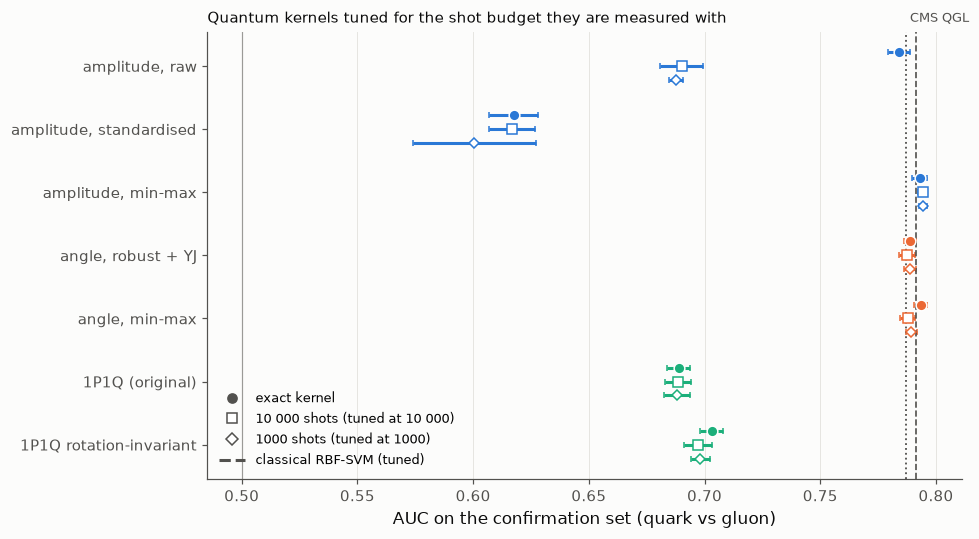

In [5]:
FAM_COLOR = {"amplitude": COLORS["series1"], "angle": COLORS["series2"], "1P1Q": COLORS["series3"]}
names = list(QUANTUM)
fig, ax = plt.subplots(figsize=(9, 5))
ypos = np.arange(len(names))[::-1]
for yp, name in zip(ypos, names):
    col = FAM_COLOR[QUANTUM[name][0]]
    e = exact_stat(name, "conf_auc"); a1 = shot_stat(name, 1000); a10 = shot_stat(name, 10000)
    ax.errorbar(e[0], yp + 0.22, xerr=e[1], fmt="o", color=col, markersize=7, markeredgecolor="white", capsize=2)
    ax.errorbar(a10[0], yp, xerr=a10[1], fmt="s", mfc="white", color=col, markersize=6, capsize=2)
    ax.errorbar(a1[0], yp - 0.22, xerr=a1[1], fmt="D", mfc="white", color=col, markersize=5, capsize=2)
ax.axvline(ex["qgl_conf_auc"], color=COLORS["reference"], linestyle=":", linewidth=1.2)
ax.axvline(rbf[0], color=COLORS["reference"], linestyle="--", linewidth=1.1)
ax.axvline(0.5, color=COLORS["reference"], linewidth=0.8, alpha=0.5)
ax.text(ex["qgl_conf_auc"], len(names) - 0.35, " CMS QGL", fontsize=8.5, color=COLORS["reference"], va="bottom")
ax.set_yticks(ypos, names)
ax.set_xlabel("AUC on the confirmation set (quark vs gluon)")
ax.grid(axis="y", visible=False)
handles = [Line2D([], [], color=COLORS["reference"], marker="o", linestyle="", label="exact kernel"),
           Line2D([], [], color=COLORS["reference"], marker="s", mfc="white", linestyle="", label="10 000 shots (tuned at 10 000)"),
           Line2D([], [], color=COLORS["reference"], marker="D", mfc="white", linestyle="", label="1000 shots (tuned at 1000)"),
           Line2D([], [], color=COLORS["reference"], linestyle="--", label="classical RBF-SVM (tuned)")]
ax.legend(handles=handles, loc="lower left", fontsize=8.5)
ax.set_title("Quantum kernels tuned for the shot budget they are measured with", loc="left", fontsize=10)
fig.tight_layout()
save(fig, "fig12_shot_aware_tuning")
plt.show()

## 4. Summary for the research log

In [6]:
print("- Shot-aware tuning (CV on finite-shot kernels), confirmation set:")
for name in QUANTUM:
    e = exact_stat(name, "conf_auc"); e1 = exact_stat(name, "conf_auc_1000"); a1 = shot_stat(name, 1000); a10 = shot_stat(name, 10000)
    print(f"  - {name}: exact {e[0]:.3f}; 1k shots exact-tuned {e1[0]:.3f} -> shot-tuned {a1[0]:.3f}; 10k shots {a10[0]:.3f}")

- Shot-aware tuning (CV on finite-shot kernels), confirmation set:
  - amplitude, raw: exact 0.784; 1k shots exact-tuned 0.591 -> shot-tuned 0.688; 10k shots 0.690
  - amplitude, standardised: exact 0.617; 1k shots exact-tuned 0.579 -> shot-tuned 0.601; 10k shots 0.617
  - amplitude, min-max: exact 0.793; 1k shots exact-tuned 0.776 -> shot-tuned 0.794; 10k shots 0.794
  - angle, robust + YJ: exact 0.789; 1k shots exact-tuned 0.789 -> shot-tuned 0.789; 10k shots 0.788
  - angle, min-max: exact 0.793; 1k shots exact-tuned 0.756 -> shot-tuned 0.789; 10k shots 0.788
  - 1P1Q (original): exact 0.689; 1k shots exact-tuned 0.688 -> shot-tuned 0.688; 10k shots 0.689
  - 1P1Q rotation-invariant: exact 0.703; 1k shots exact-tuned 0.592 -> shot-tuned 0.698; 10k shots 0.697
